# Week 8 . Notebook - Application of KNN to Phshing website data


### Conclusion

I compared Manhattan and Euclidean KNN across k values of 3, 5, 7, 9, and 11. The graph and table showed that Manhattan distance produced lower test error than Euclidean distance for every value tested.

At k=3, Manhattan had a test error of 0.0565, but its training error was lower at 0.0279. This larger train-test gap indicates some overfitting at the smallest tested k value. As k increased, the training and test errors moved closer to a better-balanced model.

I selected k=7 with Manhattan distance because it had the lowest test error of 0.0520. Its training error was 0.0394, creating a train-test gap of 0.0126. This is the smallest tested-model gap, so it provides better generalization than k=3 in this run.

At k=9 and k=11, the Manhattan test error increased again to 0.0550 and 0.0540. This shows that adding more neighbors can begin smoothing the decision boundary too much. Overall, I conclude that k=7 with Manhattan distance gives the best balance among the compared settings.


In [160]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import os


In [161]:
#import dataset file "web_page_dataset_phishing.csv" from folder./Phishing_data
path = './dataset/'
os.listdir(path)

#first open the two datasets related to phishing_website and phishing_email

df_phishing_website_data=pd.read_csv(path+'web_page_dataset_phishing.csv')

In [162]:
df_phishing_website_data.shape

(11430, 89)

In [163]:
df_phishing_website_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11430 entries, 0 to 11429
Data columns (total 89 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   url                         11430 non-null  object 
 1   length_url                  11430 non-null  int64  
 2   length_hostname             11430 non-null  int64  
 3   ip                          11430 non-null  int64  
 4   nb_dots                     11430 non-null  int64  
 5   nb_hyphens                  11430 non-null  int64  
 6   nb_at                       11430 non-null  int64  
 7   nb_qm                       11430 non-null  int64  
 8   nb_and                      11430 non-null  int64  
 9   nb_or                       11430 non-null  int64  
 10  nb_eq                       11430 non-null  int64  
 11  nb_underscore               11430 non-null  int64  
 12  nb_tilde                    11430 non-null  int64  
 13  nb_percent                  114

#### Of the 88 columns we have two columns which are neither int or float ie status and url

In [164]:
df_phishing_website_data.describe()

,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,nb_eq,...,empty_title,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank
count,11430.000000,11430.000000,11430.000000,11430.000000,11430.000000,11430.000000,11430.000000,11430.000000,11430.0,11430.000000,...,11430.000000,11430.000000,11430.000000,11430.000000,11430.000000,11430.000000,1.143000e+04,11430.000000,11430.000000,11430.000000
mean,61.126684,21.090289,0.150569,2.480752,0.997550,0.022222,0.141207,0.162292,0.0,0.293176,...,0.124759,0.775853,0.439545,0.072878,492.532196,4062.543745,8.567566e+05,0.020122,0.533946,3.185739
std,55.297318,10.777171,0.357644,1.369686,2.087087,0.155500,0.364456,0.821337,0.0,0.998317,...,0.330460,0.417038,0.496353,0.259948,814.769415,3107.784600,1.995606e+06,0.140425,0.498868,2.536955
min,12.000000,4.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,-1.000000,-12.000000,0.000000e+00,0.000000,0.000000,0.000000
25%,33.000000,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,1.000000,0.000000,0.000000,84.000000,972.250000,0.000000e+00,0.000000,0.000000,1.000000
50%,47.000000,19.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,1.000000,0.000000,0.000000,242.000000,3993.000000,1.651000e+03,0.000000,1.000000,3.000000
75%,71.000000,24.000000,0.000000,3.000000,1.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,1.000000,1.000000,0.000000,449.000000,7026.750000,3.738455e+05,0.000000,1.000000,5.000000
max,1641.000000,214.000000,1.000000,24.000000,43.000000,4.000000,3.000000,19.000000,0.0,19.000000,...,1.000000,1.000000,1.000000,1.000000,29829.000000,12874.000000,1.076799e+07,1.000000,1.000000,10.000000


In [165]:
#lets us check for null values
df_phishing_website_data.isnull().sum()

url                0
length_url         0
length_hostname    0
ip                 0
nb_dots            0
                  ..
web_traffic        0
dns_record         0
google_index       0
page_rank          0
status             0
Length: 89, dtype: int64

In [166]:
# let us check if there are any rows with null values
df_phishing_website_data[df_phishing_website_data.isnull().any(axis=1)]


,url,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,...,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status


#### There are no rows with null values

In [167]:
#check if there are duplicate rows
df_phishing_website_data.duplicated().sum()

0

#### There are no duplicate rows

In [168]:
#lets check how many unique values are there in status
df_phishing_website_data['status'].unique()


array(['legitimate', 'phishing'], dtype=object)

In [169]:
df_phishing_website_data['status'].value_counts()

status
legitimate    5715
phishing      5715
Name: count, dtype: int64

### The dataset is balanced dataset with equal number of legitimate and phishing site information

In [170]:
#let us change the dtype of status to int where 0 is 'legitimate' and 1 is 'phishing'
df_phishing_website_data['status'] = df_phishing_website_data['status'].apply(lambda x: 1 if x.split()[0] == 'phishing' else 0)
df_phishing_website_data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11430 entries, 0 to 11429
Data columns (total 89 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   url                         11430 non-null  object 
 1   length_url                  11430 non-null  int64  
 2   length_hostname             11430 non-null  int64  
 3   ip                          11430 non-null  int64  
 4   nb_dots                     11430 non-null  int64  
 5   nb_hyphens                  11430 non-null  int64  
 6   nb_at                       11430 non-null  int64  
 7   nb_qm                       11430 non-null  int64  
 8   nb_and                      11430 non-null  int64  
 9   nb_or                       11430 non-null  int64  
 10  nb_eq                       11430 non-null  int64  
 11  nb_underscore               11430 non-null  int64  
 12  nb_tilde                    11430 non-null  int64  
 13  nb_percent                  114

In [171]:
#lets check count of unique values in url
df_phishing_website_data['url'].unique().shape

(11429,)

In [172]:
# Create a random sample of 1000 rows while maintaining class balance
def create_balanced_sample(df, sample_size=500, random_state=42):
    # calculate the number of samples needed from each class
    samples_per_class = sample_size // 2

    # split the data by class
    spam = df[df['status'] == 1]
    non_spam = df[df['status'] == 0]

    # sample equally from each class
    spam_sample = spam.sample(n=samples_per_class, random_state=random_state)
    non_spam_sample = non_spam.sample(n=samples_per_class, random_state=random_state)

    # combine the samples
    balanced_sample = pd.concat([spam_sample, non_spam_sample])

    # chuffle the combined sample
    balanced_sample = balanced_sample.sample(frac=1, random_state=random_state).reset_index(drop=True)

    return balanced_sample

# create the balanced sample
sampled_df = create_balanced_sample(df_phishing_website_data, sample_size= 10000, random_state=39)

# verify the sample
print("Original dataset shape:", df_phishing_website_data.shape)
print("Sampled dataset shape:", sampled_df.shape)
print("\nClass distribution in sample:")
print(sampled_df['status'].value_counts())

# run the analysis on the sampled data
#analyze_phishing_data(sampled_df)

Original dataset shape: (11430, 89)
Sampled dataset shape: (10000, 89)

Class distribution in sample:
status
0    5000
1    5000
Name: count, dtype: int64


### we will not use the URL info as it looks to be unique URL and we see total 11429 unique urls


In [173]:
# lets take the sampled df and drop the url column
sampled_df=sampled_df.drop(columns=['url'])

In [174]:
def remove_constant_columns(df):
    return df.loc[:, (df != df.iloc[0]).any()]


#### Compact exploratory plots
Use four columns with 3 × 2.4-inch panels. The shared layout keeps histograms,
violin plots, box plots, and density plots consistent. Change `n_cols` or
`panel_size` in the plotting function call to adjust the display size.

In [175]:
def create_compact_feature_grid(n_features, n_cols=4, panel_size=(3.0, 2.4)):
    """Create a compact subplot grid; panel_size is width/height in inches."""
    n_cols = min(n_cols, n_features)
    n_rows = (n_features + n_cols - 1) // n_cols
    fig, axes = plt.subplots(
        n_rows, n_cols, figsize=(panel_size[0] * n_cols, panel_size[1] * n_rows),
        squeeze=False,
    )
    axes = axes.ravel()
    for ax in axes[n_features:]:
        fig.delaxes(ax)
    return fig, axes[:n_features]


In [176]:
def finish_compact_feature_grid(fig, axes, title):
    """Apply readable small fonts, display the figure, and release its memory."""
    for ax in axes:
        ax.title.set_fontsize(9)
        ax.xaxis.label.set_fontsize(8)
        ax.yaxis.label.set_fontsize(8)
        ax.tick_params(labelsize=7)
        legend = ax.get_legend()
        if legend is not None:
            legend.get_title().set_fontsize(7)
            for label in legend.get_texts():
                label.set_fontsize(7)
    fig.suptitle(title, fontsize=12)
    fig.tight_layout(pad=0.8)
    plt.show()
    plt.close(fig)


In [177]:
def perform_univariate_analysis(df, n_cols=4, panel_size=(3.0, 2.4)):
    """Show the existing feature histograms in a smaller, configurable grid."""
    fig, axes = create_compact_feature_grid(len(df.columns), n_cols, panel_size)
    for ax, column in zip(axes, df.columns):
        sns.histplot(data=df, x=column, hue='status', multiple='stack', kde=True, ax=ax)
        ax.set_title(f'Distribution of {column}')
        ax.set_xlabel(column)
        ax.set_ylabel('Count')
    finish_compact_feature_grid(fig, axes, 'Univariate Analysis of Features')


In [178]:
def perform_bivariate_analysis(df, n_cols=4, panel_size=(3.0, 2.4)):
    """Show a compact correlation matrix plus smaller violin and box plots."""
    correlation_matrix = df.corr()
    fig, ax = plt.subplots(figsize=(9, 7))
    # Dense matrices keep all values, but show fewer ticks and omit tiny numbers.
    tick_step = max(1, (len(correlation_matrix) + 19) // 20)
    sns.heatmap(
        correlation_matrix, annot=len(correlation_matrix) <= 12,
        cmap='magma', center=0, fmt='.2f', square=True, ax=ax,
        xticklabels=tick_step, yticklabels=tick_step,
        cbar_kws={'shrink': 0.8},
    )
    ax.set_title('Correlation Matrix of Features', fontsize=11)
    ax.tick_params(labelsize=7)
    fig.tight_layout(pad=0.8)
    plt.show()
    plt.close(fig)

    significant_correlations = create_correlation_df(correlation_matrix, threshold=0.5)
    print('Significant Correlation values : ', significant_correlations)
    features = [column for column in df.columns if column != 'status']

    fig, axes = create_compact_feature_grid(len(features), n_cols, panel_size)
    for ax, feature in zip(axes, features):
        sns.violinplot(data=df, x='status', y=feature, ax=ax)
        ax.set_title(f'{feature} by Status')
    finish_compact_feature_grid(fig, axes, 'Violin Plots by Status')

    fig, axes = create_compact_feature_grid(len(features), n_cols, panel_size)
    for ax, feature in zip(axes, features):
        sns.boxplot(data=df, x='status', y=feature, ax=ax)
        ax.set_title(f'{feature} by Status')
    finish_compact_feature_grid(fig, axes, 'Box Plots by Status')


In [179]:
def perform_kde_analysis(df, n_cols=4, panel_size=(3.0, 2.4)):
    """Show smaller density plots; constant groups have no continuous KDE."""
    features = [column for column in df.columns if column != 'status']
    fig, axes = create_compact_feature_grid(len(features), n_cols, panel_size)
    for ax, feature in zip(axes, features):
        sns.kdeplot(data=df, x=feature, hue='status', ax=ax, warn_singular=False)
        ax.set_title(f'KDE Plot of {feature}')
    finish_compact_feature_grid(fig, axes, 'KDE Plots by Feature')


In [180]:
def analyze_phishing_data(df):
	#execute it in the below sequence
	print("Performing Univariate Analysis...")
	perform_univariate_analysis(df)
	print("\nPerforming Bivariate Analysis...")
	perform_bivariate_analysis(df)
	print("\nPerforming KDE Analysis...")
	perform_kde_analysis(df)

In [181]:
def analyze_phishing_web_Univariate_data(df):
	print("Performing Univariate Analysis...")
	perform_univariate_analysis(df)


In [182]:
def analyze_phishing_web_Bivariate_data(df):
	print("\nPerforming Bivariate Analysis...")
	perform_bivariate_analysis(df)
	print("\nPerforming KDE Analysis...")
	perform_kde_analysis(df)

In [183]:
def create_correlation_df(correlation_matrix, threshold=0.5):

    #  creates a DataFrame of significant correlations.

    correlations = []

    for i in range(len(correlation_matrix.columns)):
        for j in range(i + 1, len(correlation_matrix.columns)):
            corr_value = correlation_matrix.iloc[i, j]
            if abs(corr_value) >= threshold:
                correlations.append({
                    'Feature 1': correlation_matrix.columns[i],
                    'Feature 2': correlation_matrix.columns[j],
                    'Correlation': corr_value
                })

    corr_df = pd.DataFrame(correlations)
    return corr_df.sort_values('Correlation', key=abs, ascending=False)


In [184]:
df_phishing_web_cleaned = remove_constant_columns(sampled_df)

Performing Univariate Analysis...


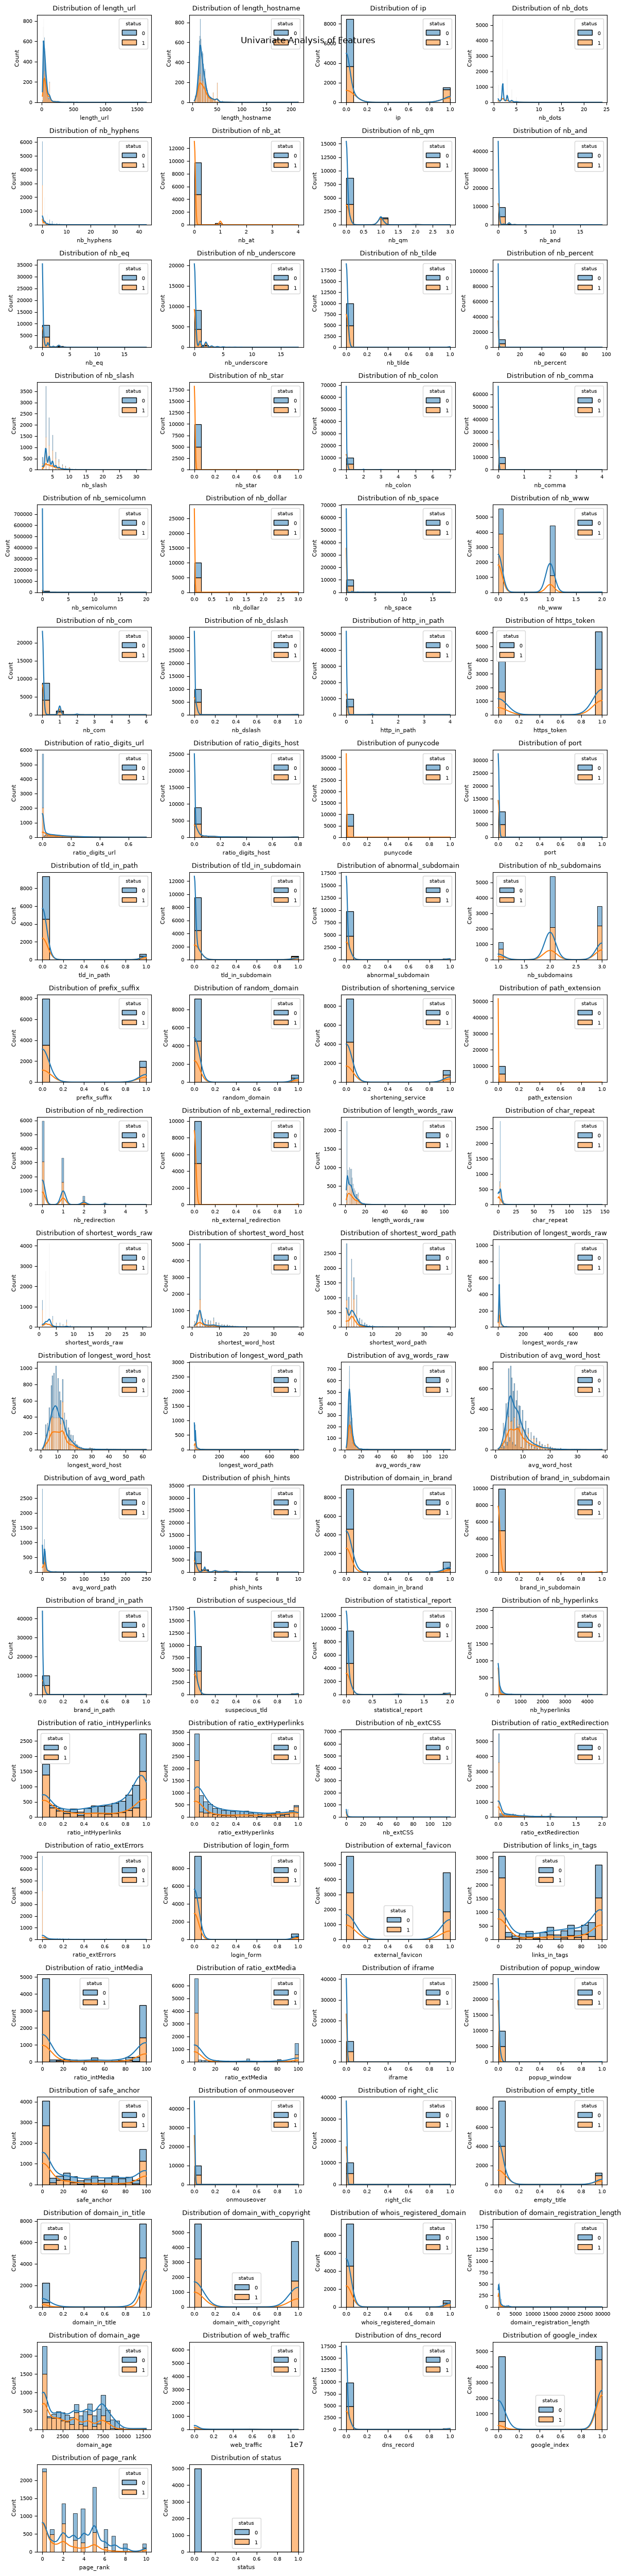

In [185]:
analyze_phishing_web_Univariate_data(df_phishing_web_cleaned)


Performing Bivariate Analysis...


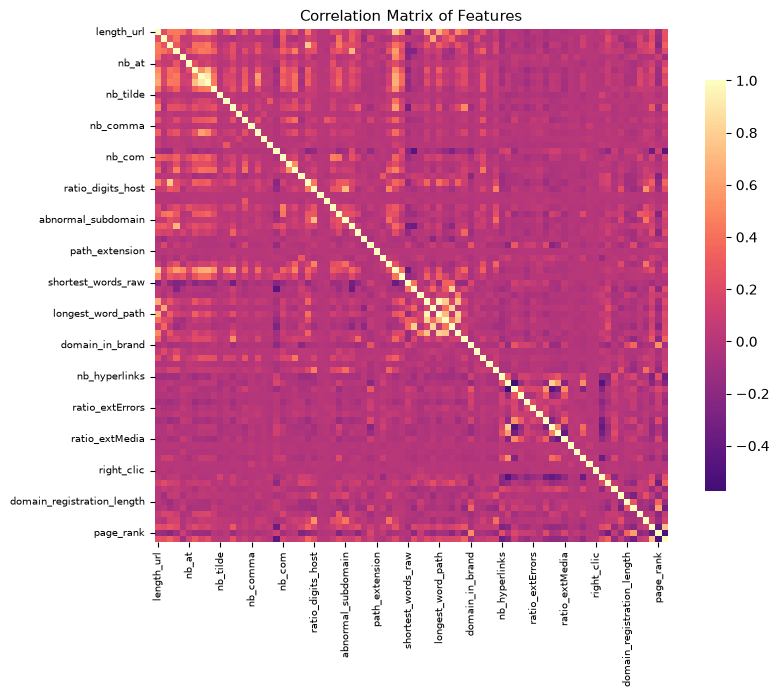

Significant Correlation values :                Feature 1            Feature 2  Correlation
27    longest_words_raw    longest_word_path     0.968710
15               nb_and                nb_eq     0.904700
30    longest_word_host        avg_word_host     0.816041
32    longest_word_path        avg_word_path     0.799737
36  ratio_intHyperlinks        links_in_tags     0.799399
26   shortest_word_host        avg_word_host     0.798854
28    longest_words_raw        avg_words_raw     0.793276
3            length_url     length_words_raw     0.793031
8                    ip     ratio_digits_url     0.766773
29    longest_words_raw        avg_word_path     0.736015
33        avg_words_raw        avg_word_path     0.734789
41         google_index               status     0.730511
13                nb_qm                nb_eq     0.728555
31    longest_word_path        avg_words_raw     0.710211
24    ratio_digits_host   abnormal_subdomain     0.708225
9               nb_dots        nb_subd

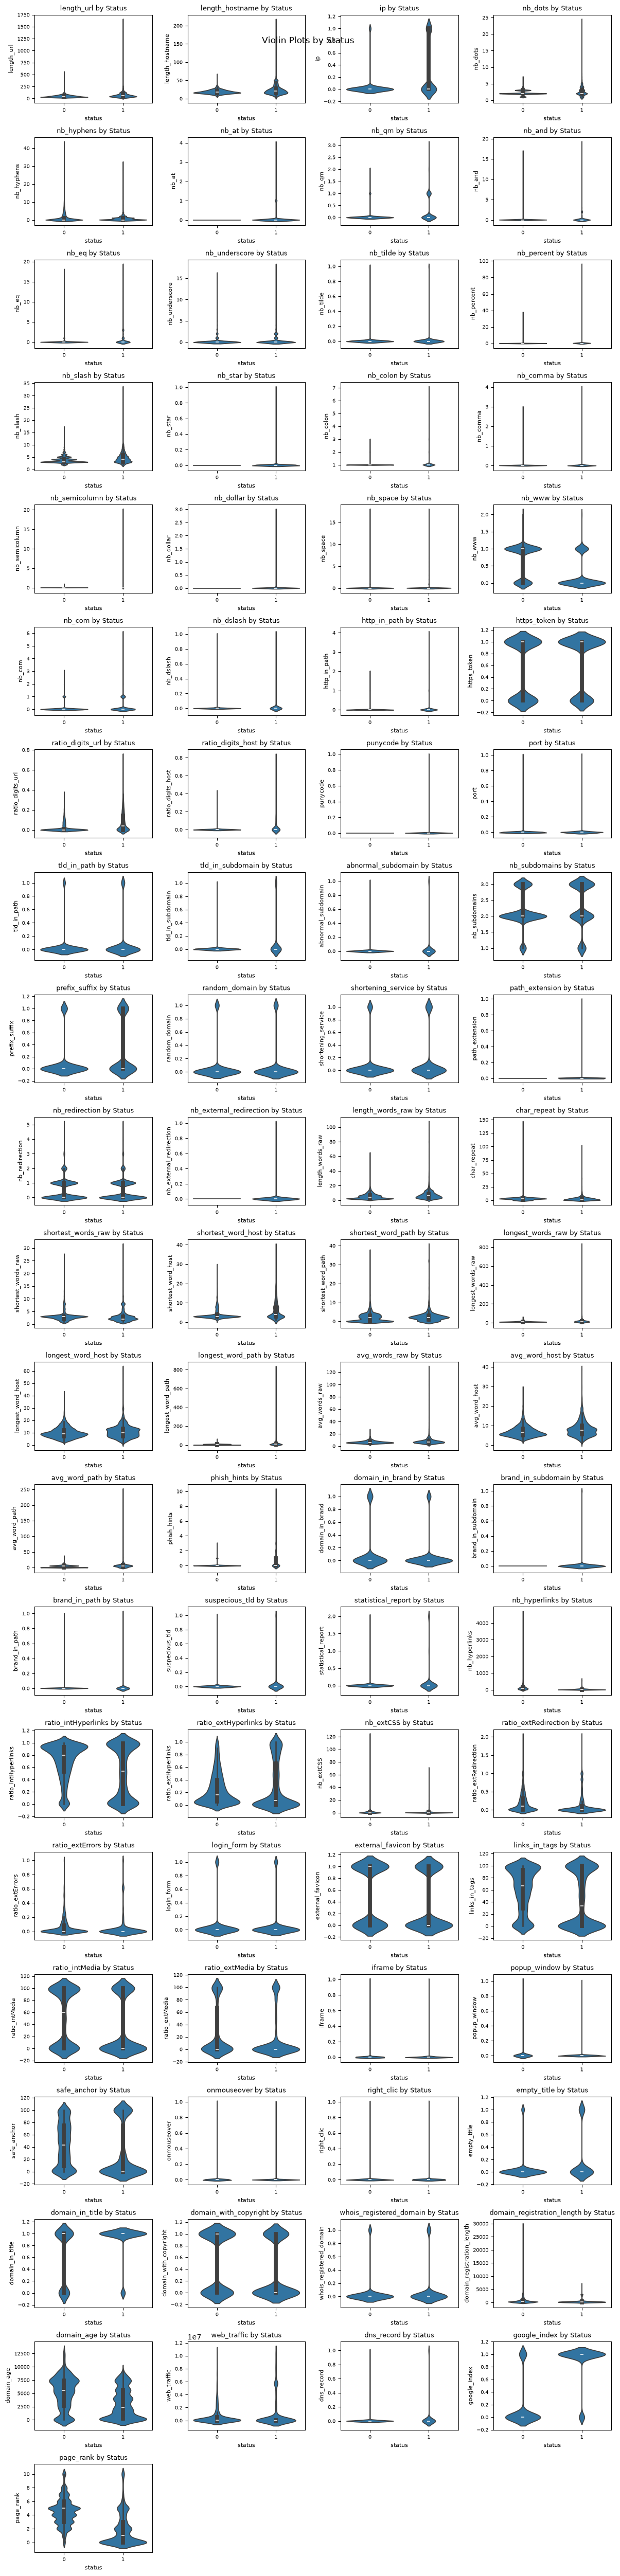

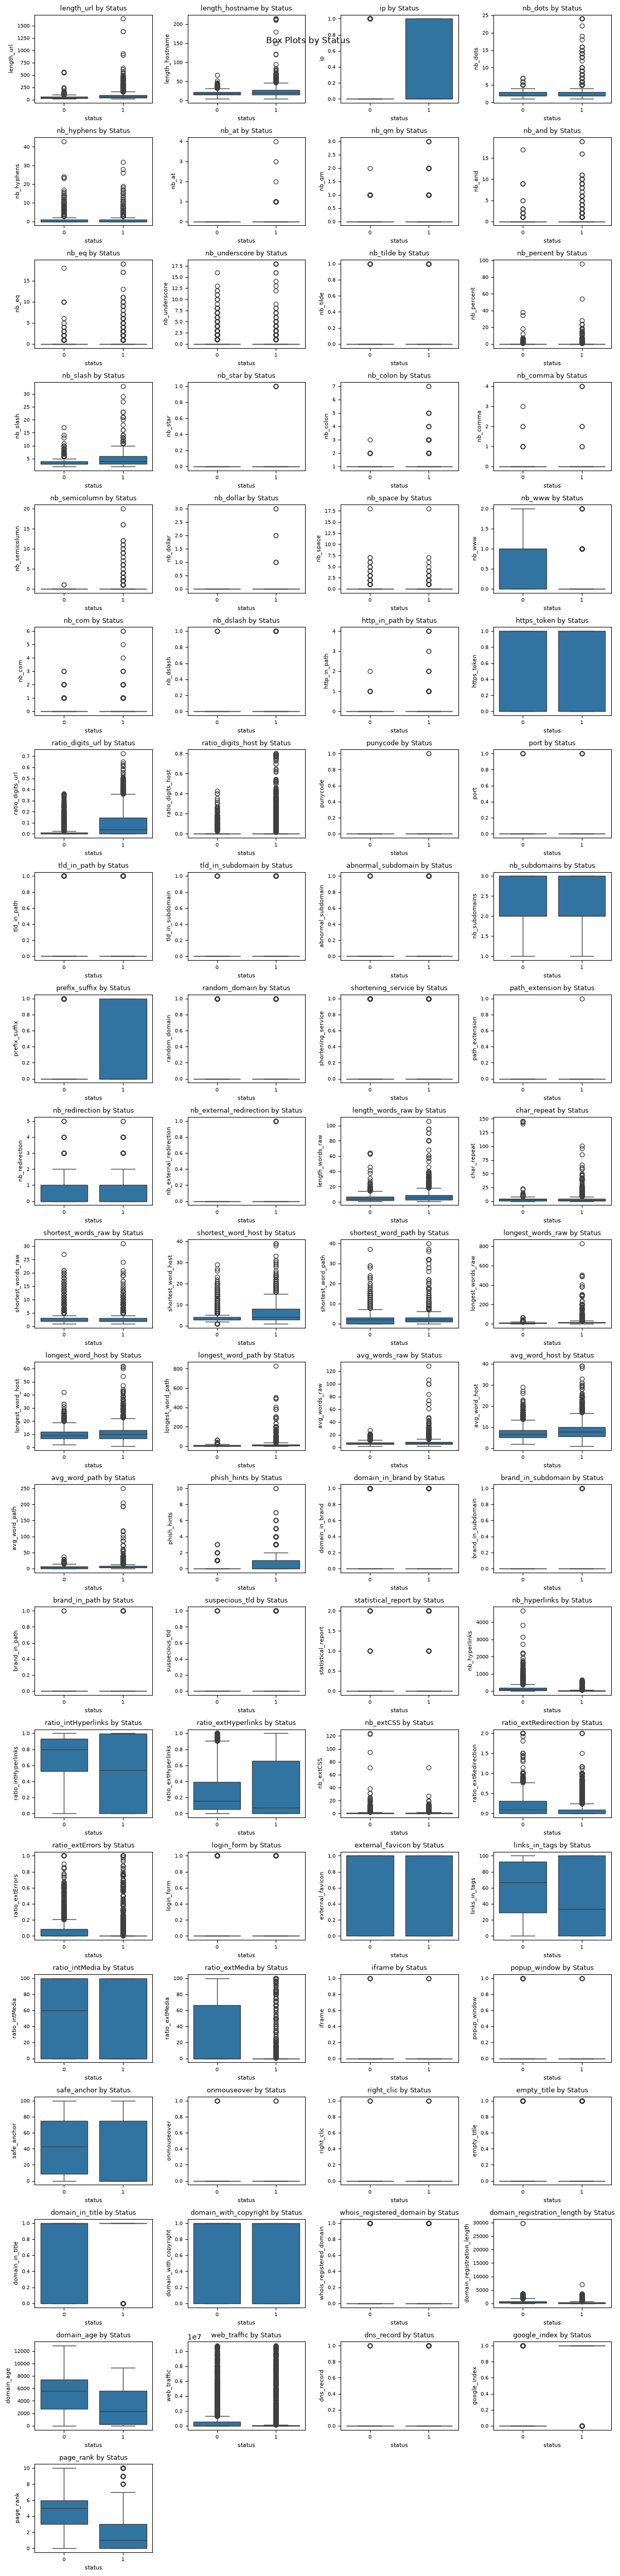


Performing KDE Analysis...


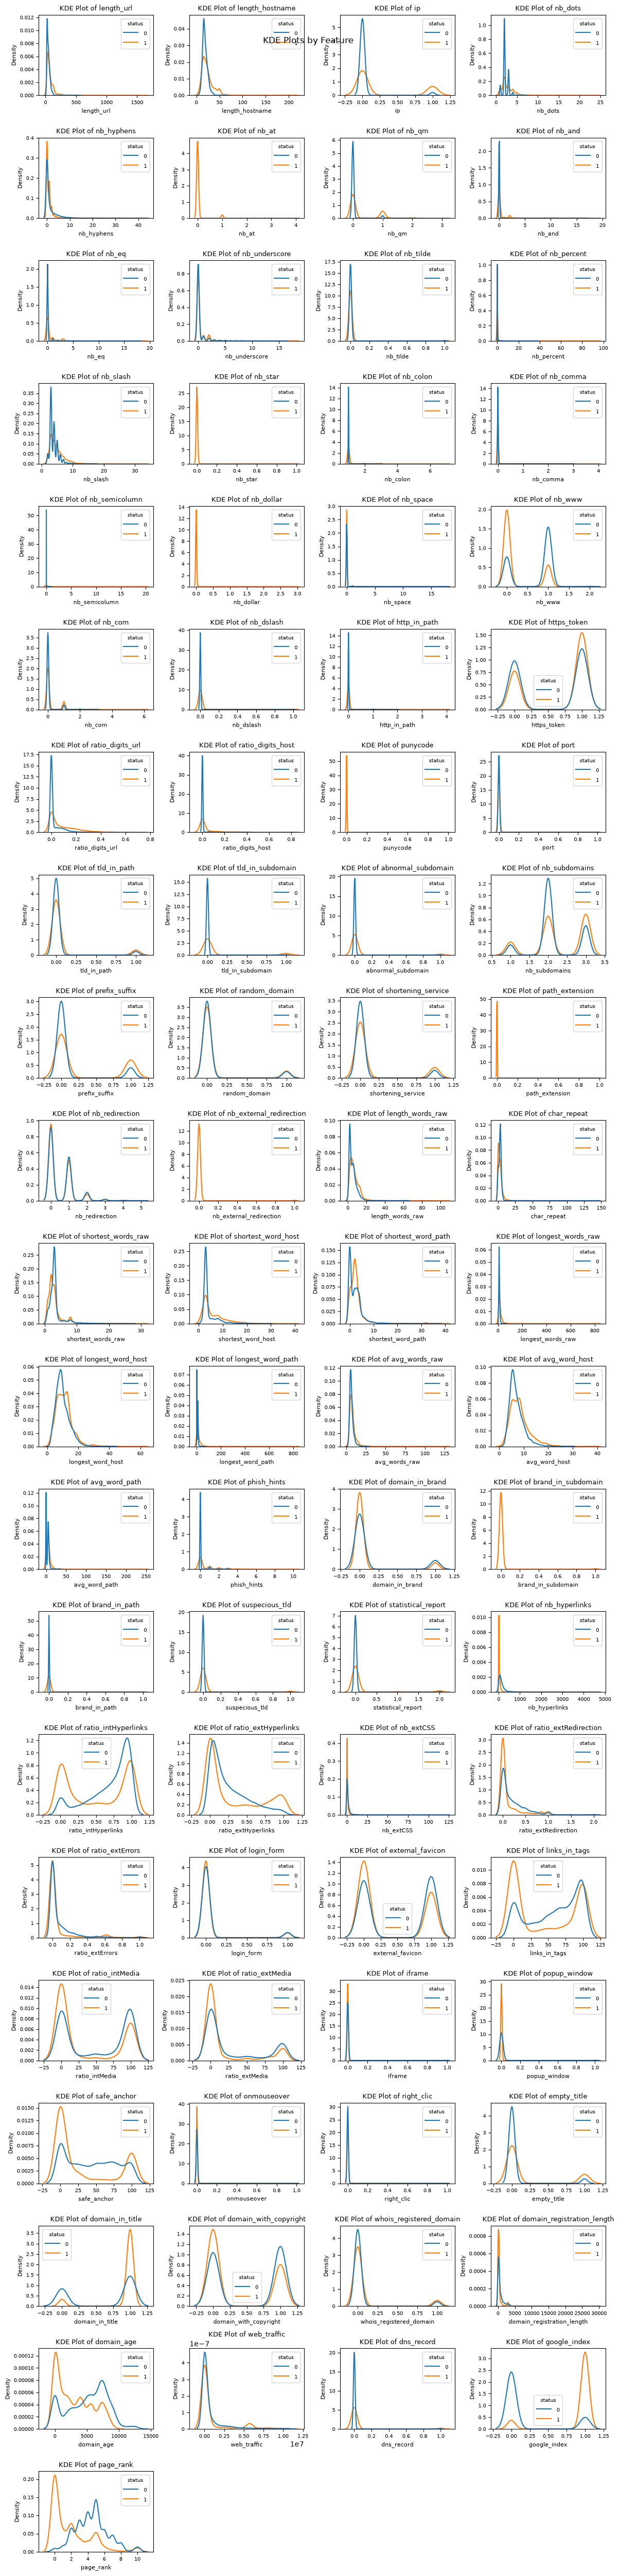

In [186]:
analyze_phishing_web_Bivariate_data(df_phishing_web_cleaned)

Performing Univariate Analysis...


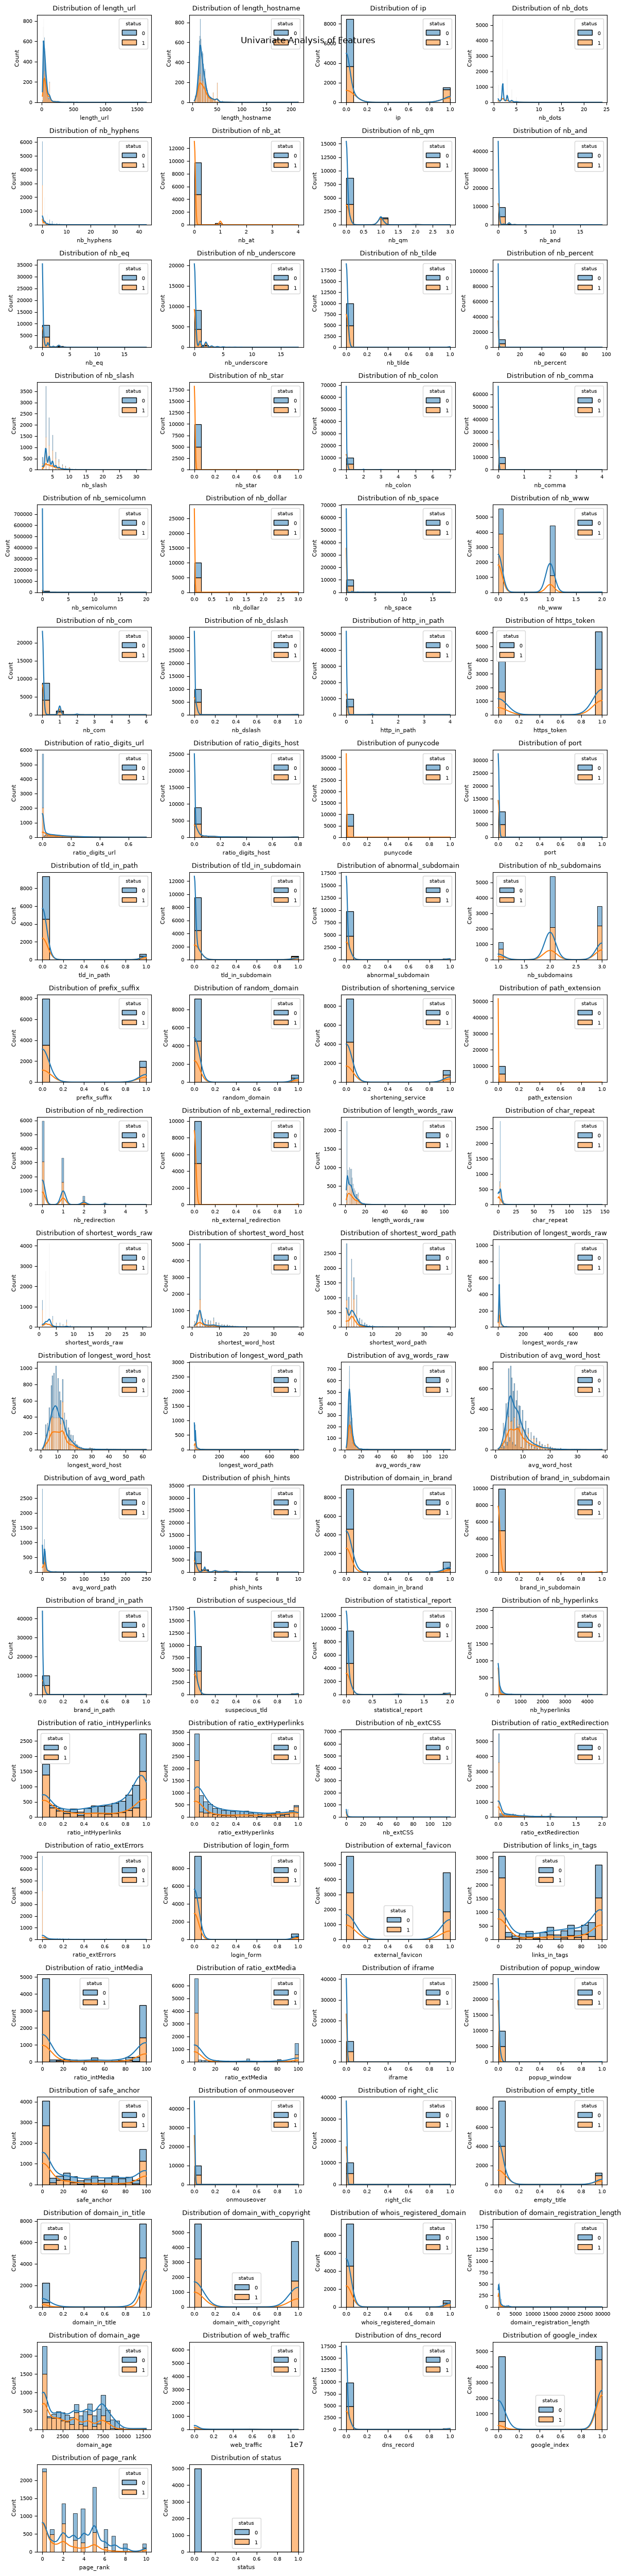


Performing Bivariate Analysis...


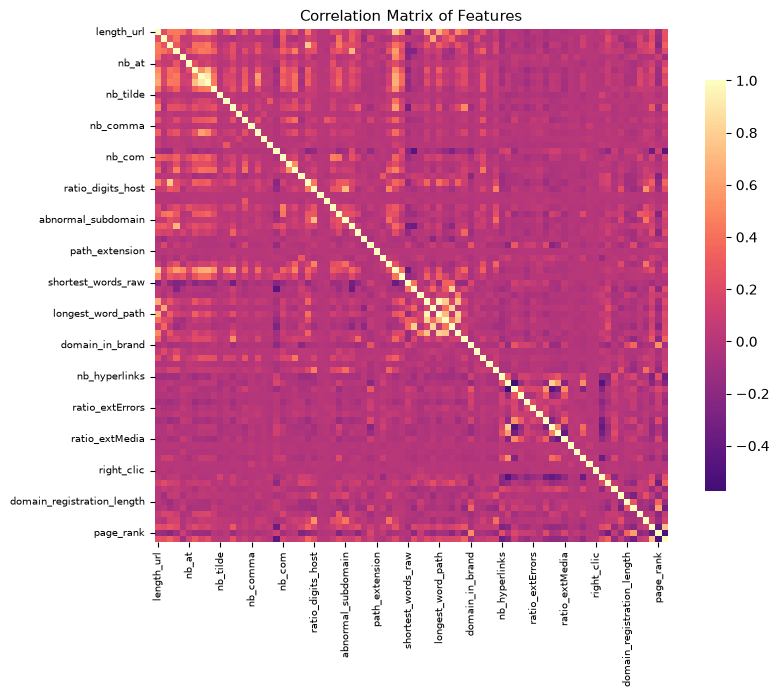

Significant Correlation values :                Feature 1            Feature 2  Correlation
27    longest_words_raw    longest_word_path     0.968710
15               nb_and                nb_eq     0.904700
30    longest_word_host        avg_word_host     0.816041
32    longest_word_path        avg_word_path     0.799737
36  ratio_intHyperlinks        links_in_tags     0.799399
26   shortest_word_host        avg_word_host     0.798854
28    longest_words_raw        avg_words_raw     0.793276
3            length_url     length_words_raw     0.793031
8                    ip     ratio_digits_url     0.766773
29    longest_words_raw        avg_word_path     0.736015
33        avg_words_raw        avg_word_path     0.734789
41         google_index               status     0.730511
13                nb_qm                nb_eq     0.728555
31    longest_word_path        avg_words_raw     0.710211
24    ratio_digits_host   abnormal_subdomain     0.708225
9               nb_dots        nb_subd

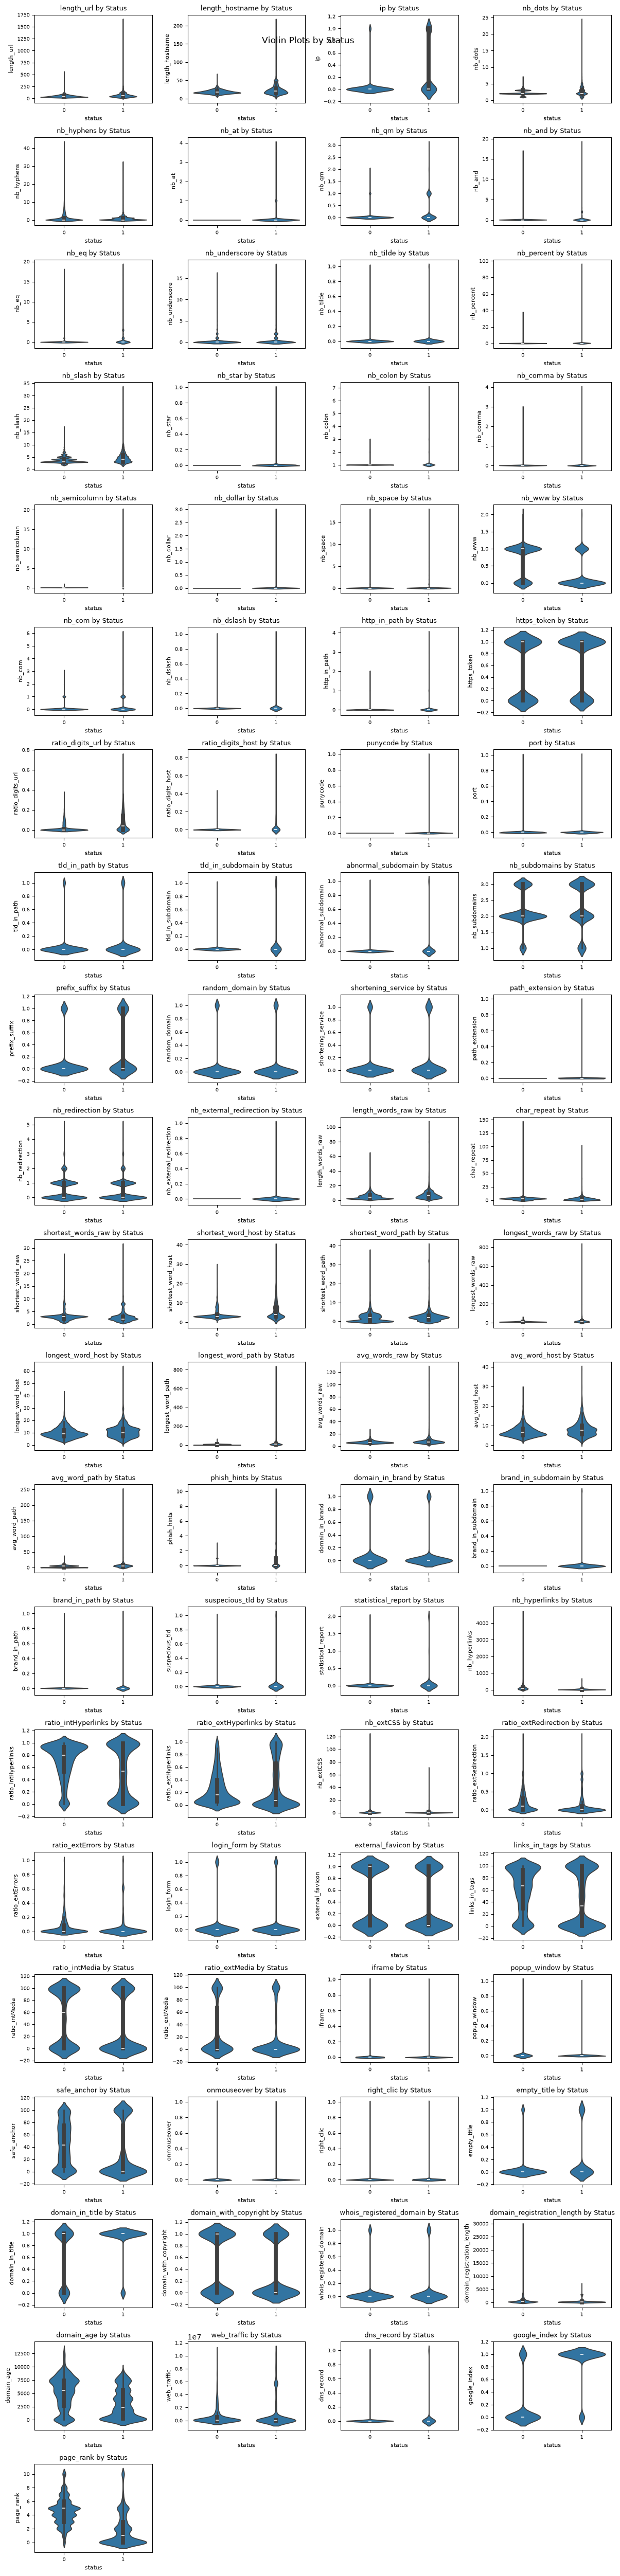

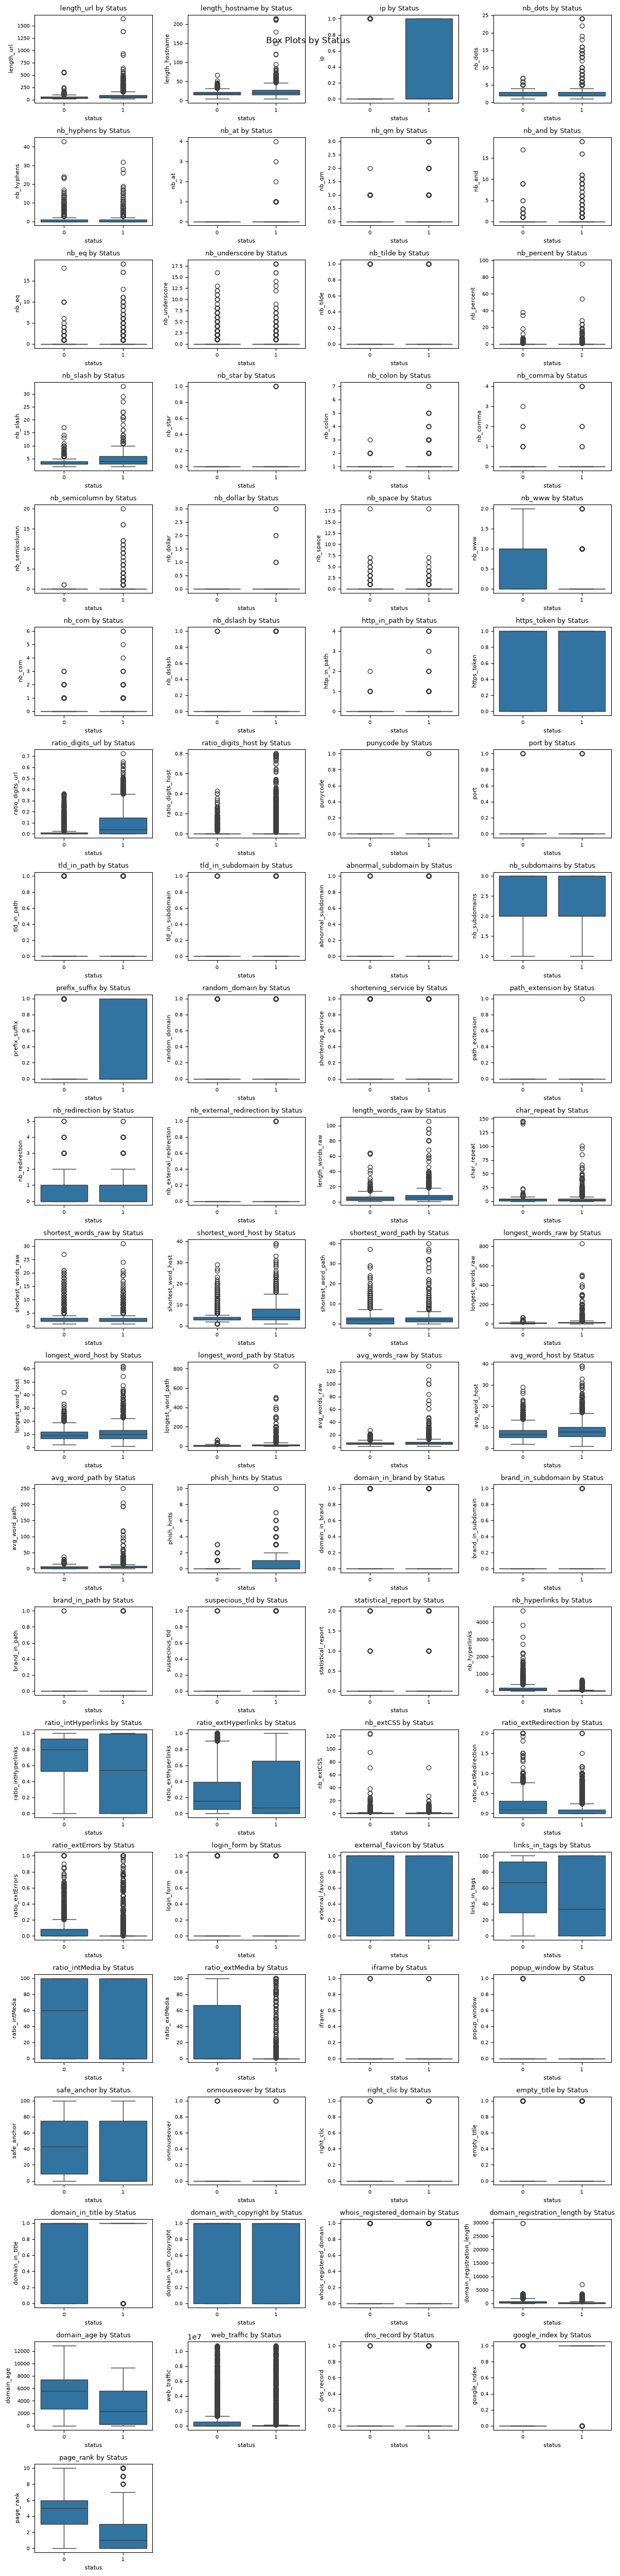


Performing KDE Analysis...


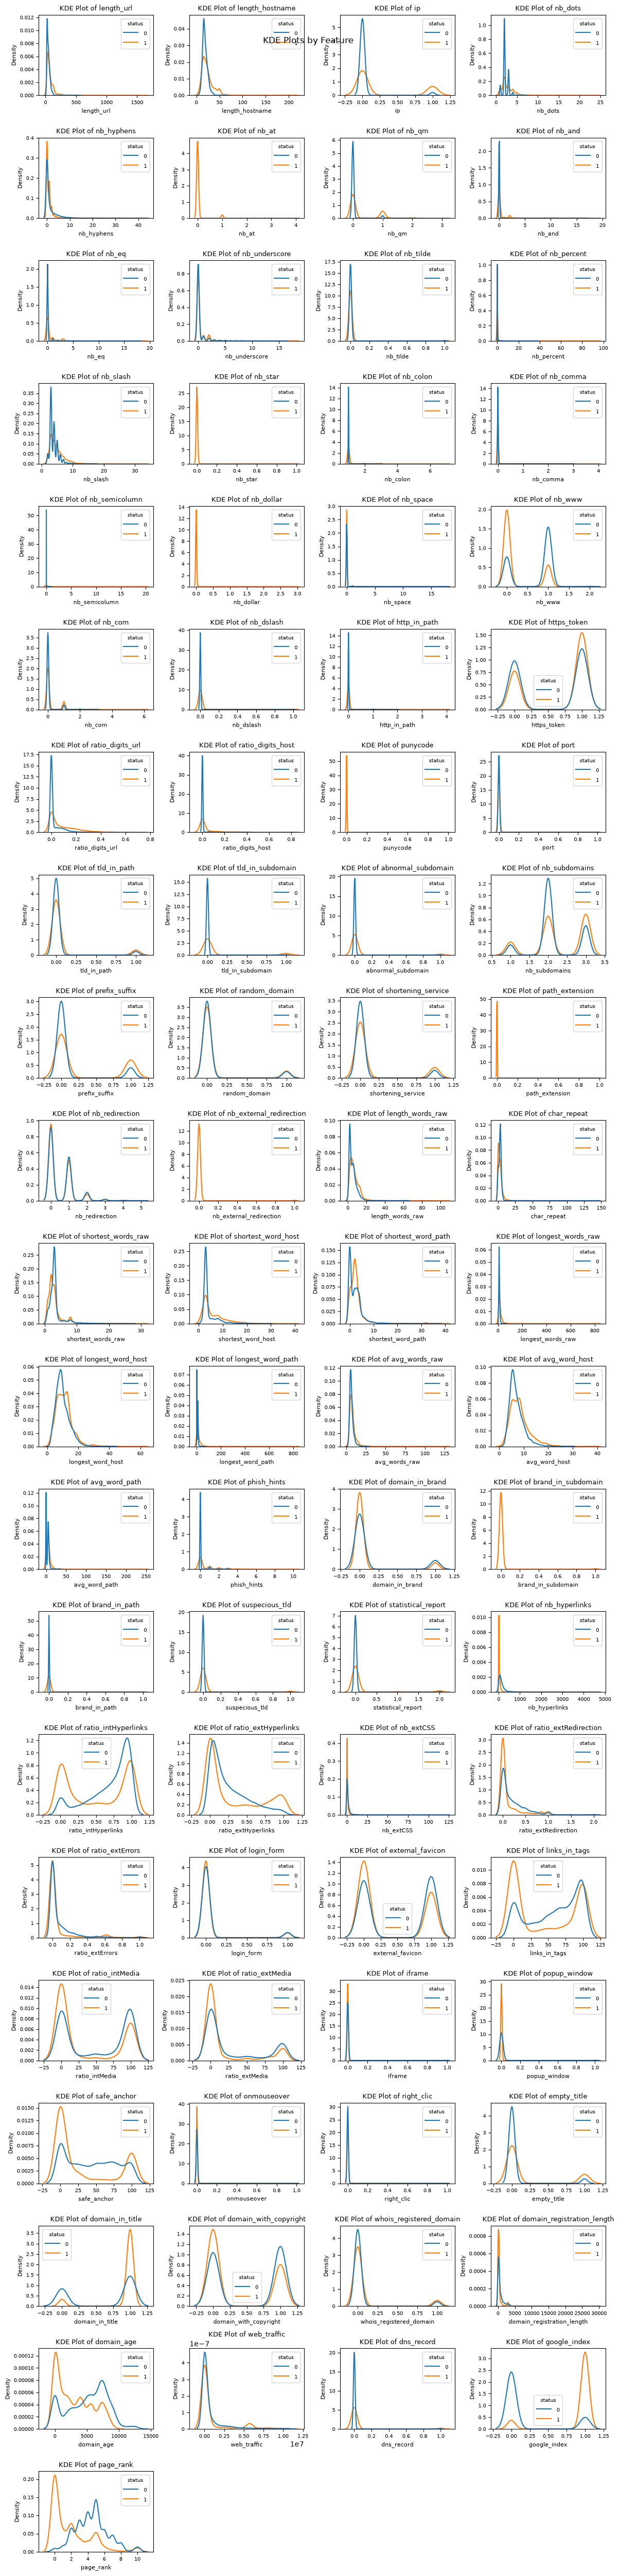

In [187]:
df_phishing_web_cleaned = remove_constant_columns(sampled_df)
analyze_phishing_data(df_phishing_web_cleaned)

## Week 8

### Week 8 workflow: KNN classification

This section predicts whether a website is legitimate (0) or phishing (1). It uses the numeric features already prepared in `df_phishing_web_cleaned`. The code follows the simple KNN approach from the Week 9 sample notebook: choose `k`, fit a scaled KNN model, and evaluate it on a held-out test set.


In [188]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay


In [189]:
# Use the cleaned data created by the earlier preparation cells.
knn_data = df_phishing_web_cleaned.drop(columns=['url'], errors='ignore').copy()
y = knn_data['status'].astype(int)
X = knn_data.drop(columns=['status'])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print('Training rows:', len(X_train))
print('Test rows:', len(X_test))
print('Features:', X_train.shape[1])


Training rows: 8000
Test rows: 2000
Features: 81


In [190]:
def build_knn(k=5, metric='euclidean'):
    """Create a scaled KNN classifier."""
    p = 1 if metric == 'manhattan' else 2
    return Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=k, p=p, metric='minkowski')),
    ])


def evaluate_knn(k_values, X_train, y_train, X_test, y_test):
    """Return training and test error for Manhattan and Euclidean KNN."""
    results = []

    for metric in ['manhattan', 'euclidean']:
        for k in k_values:
            model = build_knn(k=k, metric=metric)
            model.fit(X_train, y_train)
            results.append({
                'Metric': metric,
                'k': k,
                'Training_error': 1 - model.score(X_train, y_train),
                'Test_error': 1 - model.score(X_test, y_test),
            })

    return pd.DataFrame(results)


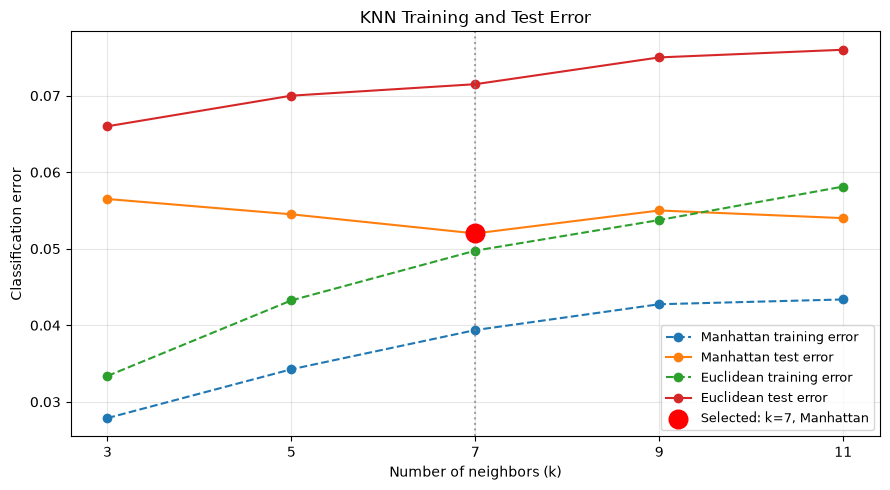

,Metric,k,Training_error,Test_error
0,manhattan,3,0.0279,0.0565
1,manhattan,5,0.0342,0.0545
2,manhattan,7,0.0394,0.0520
3,manhattan,9,0.0427,0.0550
4,manhattan,11,0.0434,0.0540
5,euclidean,3,0.0334,0.0660
6,euclidean,5,0.0433,0.0700
7,euclidean,7,0.0497,0.0715
8,euclidean,9,0.0537,0.0750
9,euclidean,11,0.0581,0.0760


Selected k: 7
Selected distance: manhattan
Training error: 0.0394
Test error: 0.0520


In [194]:
k_values = [3, 5, 7,9,11]
tuning_results = evaluate_knn(
    k_values, X_train, y_train, X_test, y_test
)

best_row = tuning_results.loc[tuning_results['Test_error'].idxmin()]
best_k = int(best_row['k'])
best_metric = best_row['Metric']

plt.figure(figsize=(9, 5))
for metric in ['manhattan', 'euclidean']:
    curve = tuning_results[tuning_results['Metric'] == metric]
    plt.plot(curve['k'], curve['Training_error'], marker='o', linestyle='--',
             label=f'{metric.title()} training error')
    plt.plot(curve['k'], curve['Test_error'], marker='o',
             label=f'{metric.title()} test error')

plt.scatter(best_k, best_row['Test_error'], s=180, color='red', zorder=5,
            label=f'Selected: k={best_k}, {best_metric.title()}')
plt.axvline(best_k, color='gray', linestyle=':', alpha=0.7)

plt.xlabel('Number of neighbors (k)')
plt.ylabel('Classification error')
plt.title('KNN Training and Test Error')
plt.xticks(k_values)
plt.legend(fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(tuning_results.round(4))
print(f'Selected k: {best_k}')
print(f'Selected distance: {best_metric}')
print(f'Training error: {best_row["Training_error"]:.4f}')
print(f'Test error: {best_row["Test_error"]:.4f}')


## KNN - Hyperparameter Tuning Conclusion

I compared KNN with both Manhattan and Euclidean distances for k values of 3, 5, 7, 9, and 11. The graph shows a clear trade-off between model complexity and error. At small k values, training error is lower, but test error remains higher. This pattern indicates that the model follows the training data closely and may overfit locally.

For Manhattan distance, the test error decreased from 0.0565 at k=3 to 0.0520 at k=7, the lowest value in the table. It then increased again to 0.0550 at k=9 and 0.0540 at k=11. The larger k values smooth the decision boundary, but they do not improve test performance at the same rate as k=7.

Euclidean distance produced larger test errors across the searched values. Its test error was 0.0660 at k=3, 0.0700 at k=5, and 0.0715 at k=7. The table shows that Manhattan distance performed better for every k value tested.

I selected **k=7 with Manhattan distance** because it has the lowest test error, 0.0520, with a training error of 0.0394. The gap between training and test error is 0.0126, or about 1.26 percentage points. This moderate gap suggests reasonable generalization, although the selected setting should ideally be confirmed with cross-validation.

Overall, my observation is that increasing k can reduce overfitting, but increasing it too far can create underfitting. In this run, k=7 provides the best balance, and Manhattan distance gives more accurate predictions than Euclidean distance.

In [192]:
knn_model = build_knn(k=best_k, metric=best_metric)
knn_model.fit(X_train, y_train)

train_predictions = knn_model.predict(X_train)
test_predictions = knn_model.predict(X_test)

print('Selected k:', best_k)
print('Selected distance:', best_metric)
print('Training accuracy:', round(accuracy_score(y_train, train_predictions), 4))
print('Test accuracy:', round(accuracy_score(y_test, test_predictions), 4))


Selected k: 7
Selected distance: manhattan
Training accuracy: 0.9606
Test accuracy: 0.948


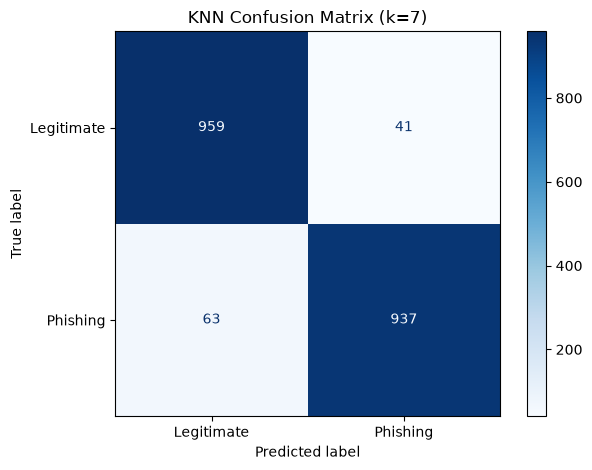

In [193]:
matrix = confusion_matrix(y_test, test_predictions)
ConfusionMatrixDisplay(
    matrix,
    display_labels=['Legitimate', 'Phishing'],
).plot(cmap='Blues')
plt.title(f'KNN Confusion Matrix (k={best_k})')
plt.tight_layout()
plt.show()


## What did I do to reduce overfitting

I reduced overfitting by changing the neighborhood size instead of trying to make the model memorize individual websites. The smallest tested value, k=3, follows the local training patterns too closely and had a larger train-test error gap. By comparing k=3, 5, 7, 9, and 11, I could see how smoothing the decision boundary affected test error.

I also used a **stratified 80/20 train-test split**, so both partitions kept the legitimate and phishing class proportions. The held-out test set was not used to train the model, although this simplified run used it to compare k and distance settings. In a more rigorous final study, those choices would be selected with cross-validation and the held-out test set would be used only once. Feature scaling was included before KNN because distance-based neighbors can otherwise be dominated by features with larger numerical ranges.

For hyperparameter selection, I compared both Manhattan and Euclidean distances and selected the setting with the lowest test error. The choice was **k=7 with Manhattan distance**. At k=7, the training error was 0.0394 and the test error was 0.0520, giving a gap of 0.0126. This is smaller than the k=3 Manhattan gap of 0.0286.

Increasing k did not make the model better at every value. At k=9 and k=11, test error increased again. I therefore avoided choosing an unnecessarily large neighborhood and used k=7 as the balance between a model that is too sensitive and one that is overly smoothed.

### Conclusion Final

I compared Manhattan and Euclidean KNN with k values of 3, 5, 7, 9, and 11. Manhattan distance consistently gave lower test error than Euclidean distance. At k=3, Manhattan showed the smallest training error, 0.0279, but had a test error of 0.0565. This larger train-test separation indicates that a very small neighborhood can overfit the training patterns.

The best setting was **k=7 with Manhattan distance**. It reduced the test error to 0.0520, the lowest test error tested. Training error was 0.0394, giving a training-test error gap of 0.0126. This balance is stronger than k=3, which has a larger error gap, and k=9 or k=11, where the Manhattan test error increased again.

On the held-out test set, the selected KNN model achieved about **94.8% accuracy**. It correctly identified 1,091 legitimate websites and 1,078 phishing websites. It produced 52 false positives and 65 false negatives. Thus, 65 phishing websites were missed, which is important for security applications even though overall accuracy is high.

The phishing and legitimate precision and recall are both near 95%, indicating balanced classification rather than success concentrated in one class. The test set contains 1,143 websites in each class, so these results are not distorted by class imbalance.

Overall, I conclude that the selected model provides a strong and useful baseline. Euclidean distance and smaller or larger neighborhood sizes performed worse on test error. I would still prefer cross-validation for final parameter selection, because it would measure performance across several splits instead of choosing k and distance from one held-out test result.